# Exploratory Data Analysis (EDA)


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "processed").exists() and (ROOT.parent / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

required = ["jigsaw_cleaned.csv", "jigsaw_official_test.csv", "sms_cleaned.csv", "unified_master.csv"]
missing = [name for name in required if not (DATA / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run src/prepare_data.py first.")

jigsaw = pd.read_csv(DATA / "jigsaw_cleaned.csv")
official_test = pd.read_csv(DATA / "jigsaw_official_test.csv")
sms = pd.read_csv(DATA / "sms_cleaned.csv")
master = pd.read_csv(DATA / "unified_master.csv")
manifest = json.loads((DATA / "data_manifest.json").read_text(encoding="utf-8"))
print(f"Project root: {ROOT}")
print(f"Processed data: {DATA}")

Project root: /Users/kakulrajput/Documents/Community_App_ML
Processed data: /Users/kakulrajput/Documents/Community_App_ML/data/processed


/var/folders/44/fywnm5sj335fdzvrq6s4_m3c0000gn/T/ipykernel_25576/639995592.py:21: DtypeWarning: Columns (4: spam_label) have mixed types. Specify dtype option on import or set low_memory=False.
  master = pd.read_csv(DATA / "unified_master.csv")


## Dataset sizes

,dataset,rows
0,Jigsaw labeled train,159571
1,Jigsaw official test,153163
2,SMS Spam Collection,5160
3,Unified master,317894


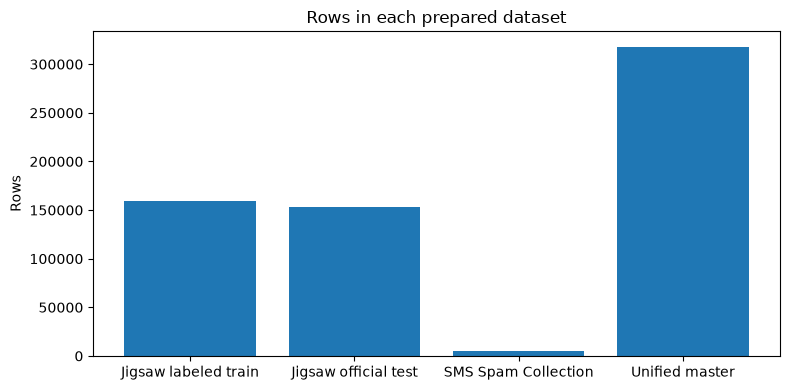

In [2]:
summary = pd.DataFrame({
    "dataset": ["Jigsaw labeled train", "Jigsaw official test", "SMS Spam Collection", "Unified master"],
    "rows": [len(jigsaw), len(official_test), len(sms), len(master)],
})
display(summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(summary["dataset"], summary["rows"])
ax.set_title("Rows in each prepared dataset")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()

## Toxicity label distribution

,positive_comments
toxic,15294
obscene,8449
insult,7877
severe_toxic,1595
identity_hate,1405
threat,478


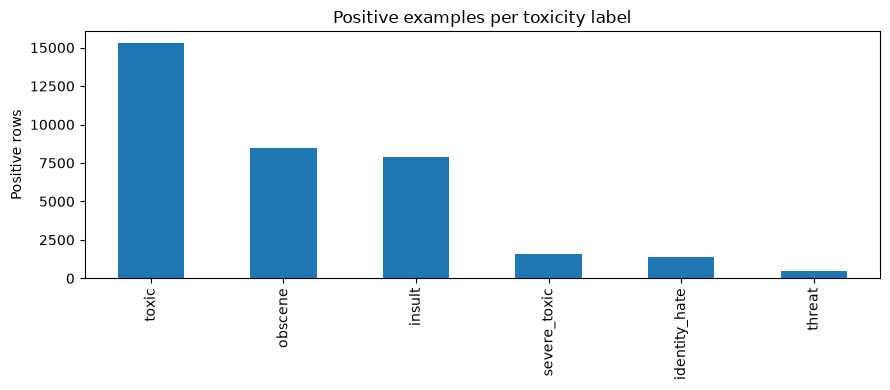

,positive_percent
toxic,9.584
obscene,5.295
insult,4.936
severe_toxic,1.000
identity_hate,0.880
threat,0.300


In [3]:
positive_counts = jigsaw[LABELS].sum().sort_values(ascending=False)
display(positive_counts.rename("positive_comments").to_frame())

fig, ax = plt.subplots(figsize=(9, 4))
positive_counts.plot(kind="bar", ax=ax)
ax.set_title("Positive examples per toxicity label")
ax.set_ylabel("Positive rows")
plt.tight_layout()
plt.show()

label_rates = (jigsaw[LABELS].mean() * 100).sort_values(ascending=False)
display(label_rates.rename("positive_percent").round(3).to_frame())

## SMS ham/spam balance

,rows
spam_label,
ham,4518
spam,642


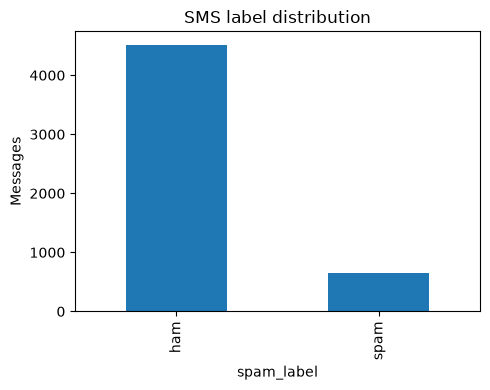

In [4]:
sms_counts = sms["spam_label"].value_counts(dropna=False)
display(sms_counts.rename("rows").to_frame())

fig, ax = plt.subplots(figsize=(5, 4))
sms_counts.plot(kind="bar", ax=ax)
ax.set_title("SMS label distribution")
ax.set_ylabel("Messages")
plt.tight_layout()
plt.show()

## Text length distributions

,text_length
count,159571.00
mean,390.93
std,586.36
min,6.00
25%,94.00
50%,204.00
75%,432.00
max,5000.00


,text_length
count,5160.00
mean,79.07
std,58.20
min,2.00
25%,36.00
50%,61.00
75%,118.00
max,910.00


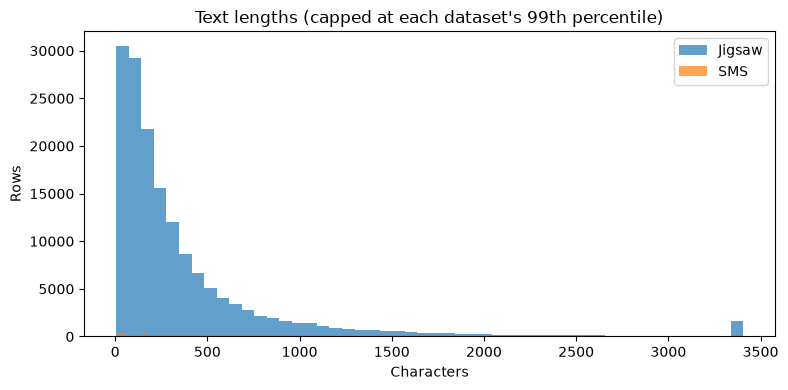

In [5]:
jigsaw["text_length"] = jigsaw["text"].fillna("").str.len()
sms["text_length"] = sms["text"].fillna("").str.len()
display(jigsaw["text_length"].describe().to_frame().round(2))
display(sms["text_length"].describe().to_frame().round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(jigsaw["text_length"].clip(upper=jigsaw["text_length"].quantile(0.99)), bins=50, alpha=0.7, label="Jigsaw")
ax.hist(sms["text_length"].clip(upper=sms["text_length"].quantile(0.99)), bins=50, alpha=0.7, label="SMS")
ax.set_title("Text lengths (capped at each dataset's 99th percentile)")
ax.set_xlabel("Characters")
ax.set_ylabel("Rows")
ax.legend()
plt.tight_layout()
plt.show()

## Data quality checks

In [6]:
quality = pd.DataFrame({
    "check": ["Empty Jigsaw text", "Duplicate Jigsaw IDs", "Duplicate Jigsaw text", "Empty SMS text", "Duplicate SMS text", "Rows in official test", "Labeled official test rows"],
    "value": [
        int(jigsaw["text"].fillna("").str.strip().eq("").sum()),
        int(jigsaw["id"].duplicated().sum()),
        int(jigsaw["text"].duplicated().sum()),
        int(sms["text"].fillna("").str.strip().eq("").sum()),
        int(sms["text"].duplicated().sum()),
        int(len(official_test)),
        int(manifest.get("jigsaw_official_test_labeled_rows", 0)),
    ],
})
display(quality)
display(pd.Series(manifest, name="value").to_frame())

,check,value
0,Empty Jigsaw text,0
1,Duplicate Jigsaw IDs,0
2,Duplicate Jigsaw text,197
3,Empty SMS text,0
4,Duplicate SMS text,0
5,Rows in official test,153163
6,Labeled official test rows,63978


,value
jigsaw_train_clean_rows,159571
jigsaw_official_test_rows,153163
jigsaw_test_labels_raw_rows,153164
jigsaw_official_test_labeled_rows,63978
jigsaw_sample_submission_rows,153164
sms_clean_rows,5160
unified_master_rows,317894
toxicity_train_rows,127656
toxicity_validation_rows,15957
toxicity_test_rows,15958


## Interpretation

- Toxicity labels are imbalanced, so accuracy alone is not sufficient for evaluation.
- Macro F1 helps show performance on less frequent labels; micro F1 summarizes all label decisions together.
- The official Jigsaw test set is separate from the train/validation/test split used for local model development.
- SMS labels are ham/spam and must not be interpreted as toxicity labels.